<a href="https://colab.research.google.com/github/anthony-yt/deepwater-image-segmentation-classical-quantum/blob/feat%2Flabelling-evaluation-tools/notebooks/2_2_assisted_labelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assisted labelling with SAM

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("segment_anything") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/facebookresearch/segment-anything.git"], check=True)

import base64
import os
import time
import urllib.request
import uuid
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, JSON, display

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive, output
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/Under_Water_Dataset")
else:
    DRIVE_ROOT = Path(os.environ.get("DW_DATA_ROOT", "Under_Water_Dataset")).resolve()
PROCESSED = DRIVE_ROOT / "Dataset_Processed"

FRAMES_DIR = PROCESSED / "Frames_CLAHE"
OUTPUT_DIR = PROCESSED / "Test_Set_Curado"
SELECTION_CSV = PROCESSED / "Seleccion" / "seleccion_5_1.csv"
VIDEO = 6
OVERWRITE = False
ANNOTATOR = "Anthony"

Mounted at /content/drive


In [2]:
CKPT = DRIVE_ROOT / "checkpoints" / "sam_vit_b_01ec64.pth"
CKPT.parent.mkdir(parents=True, exist_ok=True)
if not CKPT.exists():
    urllib.request.urlretrieve("https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth", CKPT)

from segment_anything import SamPredictor, sam_model_registry

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
predictor = SamPredictor(sam_model_registry["vit_b"](checkpoint=str(CKPT)).to(device=DEVICE))
print("SAM vit_b on", DEVICE)

SAM vit_b on cpu


In [53]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LOG_CSV = PROCESSED / "Registro_Etiquetado" / f"tiempos_{ANNOTATOR}_{'todos' if VIDEO is None else 'video' + str(VIDEO)}.csv"
POINTS, SAVED = [], set()
TIMES = pd.read_csv(LOG_CSV).fillna("").to_dict("records") if LOG_CSV.exists() else []
STATE = {"frame": None, "image": None, "t0": None, "candidates": None}


def frame_ids():
    ids = sorted(p.stem for p in FRAMES_DIR.glob("*.jpg"))
    if SELECTION_CSV is not None:
        ids = [i for i in pd.read_csv(SELECTION_CSV)["frame_id"] if i in set(ids)]
    if VIDEO is not None:
        ids = [i for i in ids if f"Video{VIDEO}_" in i]
    return ids


def next_pending():
    pending = [i for i in frame_ids() if not (OUTPUT_DIR / f"{i}_mask.png").exists()]
    print(f"{len(pending)} pending of {len(frame_ids())}")
    if not pending:
        print("all frames labelled, showing the last one")
        return frame_ids()[-1]
    return pending[0]


def back():
    ids = frame_ids()
    return ids[max(ids.index(STATE["frame"]) - 1, 0)]


if IN_COLAB:
    def _add(x, y, label):
        POINTS.append((float(x), float(y), int(label)))
        return JSON({"n": len(POINTS)})

    def _undo():
        POINTS.pop() if POINTS else None
        return JSON({"n": len(POINTS)})

    def _clear():
        POINTS.clear()
        return JSON({"n": 0})

    output.register_callback("dw.add", _add)
    output.register_callback("dw.undo", _undo)
    output.register_callback("dw.clear", _clear)


def canvas(rgb):
    uid = uuid.uuid4().hex[:8]
    b64 = base64.b64encode(cv2.imencode(".png", cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))[1]).decode()
    h, w = rgb.shape[:2]
    display(HTML(f'''
<button id="u{uid}">Undo</button> <button id="c{uid}">Clear</button>
&nbsp;left click: structure &middot; right click or shift+click: background<br>
<canvas id="cv{uid}" width="{w}" height="{h}" style="cursor:crosshair;max-width:100%"></canvas>
<script>
const cv = document.getElementById("cv{uid}"), ctx = cv.getContext("2d"), img = new Image();
let pts = [];
img.src = "data:image/png;base64,{b64}";
function draw() {{
  ctx.drawImage(img, 0, 0);
  pts.forEach(p => {{ ctx.beginPath(); ctx.arc(p[0], p[1], 6, 0, 6.3); ctx.fillStyle = p[2] ? "#00ff00" : "#ff0000";
                     ctx.fill(); ctx.lineWidth = 2; ctx.strokeStyle = "#fff"; ctx.stroke(); }});
}}
img.onload = draw;
function add(e, label) {{
  const r = cv.getBoundingClientRect(), x = (e.clientX - r.left) * cv.width / r.width, y = (e.clientY - r.top) * cv.height / r.height;
  pts.push([x, y, label]); draw(); google.colab.kernel.invokeFunction("dw.add", [x, y, label], {{}});
}}
cv.addEventListener("click", e => add(e, e.shiftKey ? 0 : 1));
cv.addEventListener("contextmenu", e => {{ e.preventDefault(); add(e, 0); }});
document.getElementById("u{uid}").onclick = () => {{ pts.pop(); draw(); google.colab.kernel.invokeFunction("dw.undo", [], {{}}); }};
document.getElementById("c{uid}").onclick = () => {{ pts = []; draw(); google.colab.kernel.invokeFunction("dw.clear", [], {{}}); }};
</script>'''))


def start(frame_id):
    path = FRAMES_DIR / f"{frame_id}.jpg"
    rgb = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    POINTS.clear()
    STATE.update(frame=frame_id, image=rgb, t0=time.time(), candidates=None)
    predictor.set_image(rgb)
    print(frame_id, rgb.shape[1], "x", rgb.shape[0])
    canvas(rgb)


def preview():
    pts = np.array(POINTS)
    if len(pts) == 0:
        raise RuntimeError("Click at least one point on the frame first.")
    masks, scores, _ = predictor.predict(point_coords=pts[:, :2], point_labels=pts[:, 2].astype(int),
                                         multimask_output=len(pts) < 3)
    STATE["candidates"] = masks
    fig, axes = plt.subplots(1, len(masks), figsize=(5 * len(masks), 4), squeeze=False)
    for k, (ax, m, s) in enumerate(zip(axes[0], masks, scores)):
        ax.imshow(STATE["image"]); ax.imshow(np.ma.masked_where(~m, m), alpha=0.5, cmap="autumn")
        ax.scatter(pts[:, 0], pts[:, 1], c=np.where(pts[:, 2] == 1, "lime", "red"), edgecolors="white", s=50)
        ax.set_title(f"k={k}  score {s:.2f}  structure {m.mean():.0%}"); ax.axis("off")
    plt.show()


def save(k=0, note="", add_boxes=(), clear_boxes=(), empty=False):
    frame = STATE["frame"]
    path = OUTPUT_DIR / f"{frame}_mask.png"
    if path.exists() and not OVERWRITE and frame not in SAVED:
        raise FileExistsError(f"{path.name} already exists; set OVERWRITE = True to replace it.")
    h, w = STATE["image"].shape[:2]
    if empty:
        mask = np.zeros((h, w), bool)
    else:
        if STATE["candidates"] is None:
            raise RuntimeError("Run preview() first.")
        mask = STATE["candidates"][k].copy()
        for x0, y0, x1, y1 in add_boxes:
            mask[y0:y1, x0:x1] = True
        for x0, y0, x1, y1 in clear_boxes:
            mask[y0:y1, x0:x1] = False
    cv2.imwrite(str(path), mask.astype(np.uint8) * 255)
    check = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    assert check.shape == (h, w) and set(np.unique(check)) <= {0, 255}, "saved mask is not a single-channel 0/255 PNG"
    SAVED.add(frame)
    TIMES[:] = [t for t in TIMES if t["frame"] != frame]
    TIMES.append({"frame": frame, "seconds": round(time.time() - STATE["t0"]), "structure_pct": round(100 * mask.mean(), 1),
                  "points": len(POINTS), "note": note})
    LOG_CSV.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(TIMES).to_csv(LOG_CSV, index=False)
    print(f"saved {path.name}  ({TIMES[-1]['seconds']} s, {TIMES[-1]['structure_pct']} % structure)")


def structure_share():
    rows = [{"video": p.name.split("_frame_")[0].removeprefix("DeepWater-"),
             "structure_pct": 100 * (cv2.imread(str(p), cv2.IMREAD_GRAYSCALE) > 127).mean()}
            for p in sorted(OUTPUT_DIR.glob("*_mask.png"))]
    return pd.DataFrame(rows).groupby("video")["structure_pct"].agg(["count", "mean", "min", "max"]).round(1)


def summary():
    df = pd.DataFrame(TIMES)
    print(df.to_string(index=False))
    print(f"\nmedian {df['seconds'].median():.0f} s per frame, mean {df['seconds'].mean():.0f} s, {len(df)} frames")

## Label a frame


0 pending of 8
all frames labelled, showing the last one
DeepWater-Video6_frame_0023 480 x 360



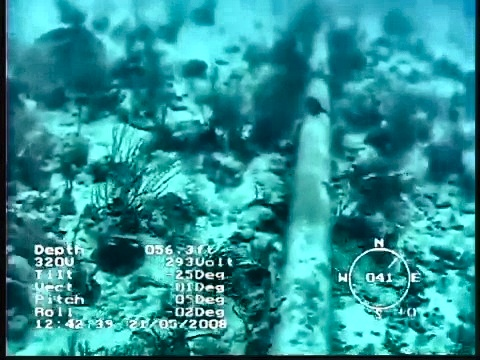

In [54]:
start(next_pending())

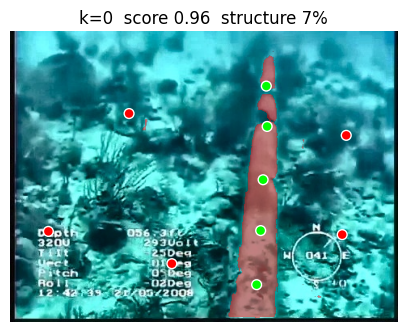

In [49]:
preview()

In [50]:
save(0)

saved DeepWater-Video6_frame_0023_mask.png  (66 s, 6.5 % structure)


In [52]:
summary()

                      frame  seconds  structure_pct  points                        note
DeepWater-Video6_frame_0000      447            4.8      14                            
DeepWater-Video6_frame_0001      671            8.1      19 manchas sueltas en el fondo
DeepWater-Video6_frame_0005      811           12.7      17             Manchas sueltas
DeepWater-Video6_frame_0009     1578           11.2      14                            
DeepWater-Video6_frame_0010      144           12.1      14                            
DeepWater-Video6_frame_0015      106            5.8      12             manchas sueltas
DeepWater-Video6_frame_0019      403            4.0      12                            
DeepWater-Video6_frame_0023       66            6.5      10                            

median 425 s per frame, mean 528 s, 8 frames


## Structure share per video (all masks in `OUTPUT_DIR`)

In [55]:
structure_share()

,count,mean,min,max
video,,,,
Video1,20,71.8,55.9,91.0
Video6,8,8.1,4.0,12.7
